# UCS420 – Cognitive Computing
## Assignment 10: Diabetes Care Information Assistant

**Student category:** Odd roll number

**Aim:** Build a Python healthcare cognitive assistant that understands diabetes-related questions, predicts the user's intent, retrieves relevant information from a small knowledge base, and gives a suitable response.

**Tools:** Python, NLTK, Scikit-learn, Matplotlib and Gradio.

> **Safety note:** This is an educational demonstration, not a medical device. It does not diagnose diabetes, set treatment targets, or recommend medication or insulin doses. For urgent symptoms, contact local emergency services or seek immediate medical care.

## Cell 1 – Install and import libraries

Run this cell first. If Colab asks you to restart the runtime after installation, do so and then run the notebook from the beginning.

In [1]:
!pip -q install nltk scikit-learn gradio matplotlib

import re
import nltk
import gradio as gr
import matplotlib.pyplot as plt

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)
from sklearn.metrics.pairwise import cosine_similarity

nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

print("Libraries imported successfully.")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully.


[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/harshitgoyal/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     /Users/harshitgoyal/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     /Users/harshitgoyal/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


## Cell 2 – Create the labelled corpus

The corpus contains 48 example questions: 8 questions for each of 6 intent categories. Each question is paired with its correct intent label.

In [2]:
queries = [
    # General information
    ("what is diabetes", "general"),
    ("explain diabetes", "general"),
    ("tell me about diabetes", "general"),
    ("what causes diabetes", "general"),
    ("what are the types of diabetes", "general"),
    ("define diabetes mellitus", "general"),
    ("what is type 1 diabetes", "general"),
    ("what is type 2 diabetes", "general"),

    # Symptoms
    ("what are the symptoms of diabetes", "symptoms"),
    ("how can i identify diabetes", "symptoms"),
    ("why do i feel very thirsty", "symptoms"),
    ("why do people with diabetes urinate frequently", "symptoms"),
    ("does diabetes cause tiredness", "symptoms"),
    ("can diabetes cause blurred vision", "symptoms"),
    ("what are early signs of diabetes", "symptoms"),
    ("does diabetes cause unexplained weight loss", "symptoms"),

    # Risk factors
    ("who is at risk of diabetes", "risk"),
    ("is diabetes hereditary", "risk"),
    ("does obesity increase diabetes risk", "risk"),
    ("can family history increase diabetes risk", "risk"),
    ("does age affect diabetes risk", "risk"),
    ("is high blood pressure a risk factor", "risk"),
    ("does lack of exercise increase risk", "risk"),
    ("can pregnancy increase diabetes risk", "risk"),

    # Prevention
    ("how can type 2 diabetes risk be reduced", "prevention"),
    ("how to reduce diabetes risk", "prevention"),
    ("can exercise help prevent type 2 diabetes", "prevention"),
    ("how does walking help health", "prevention"),
    ("how to maintain a healthy weight", "prevention"),
    ("can lifestyle changes reduce diabetes risk", "prevention"),
    ("how to lower the risk of type 2 diabetes", "prevention"),
    ("what habits support diabetes prevention", "prevention"),

    # Diet
    ("what should people with diabetes eat", "diet"),
    ("which foods are good choices for diabetes", "diet"),
    ("can people with diabetes eat fruits", "diet"),
    ("should people with diabetes limit sugary drinks", "diet"),
    ("is brown rice a whole grain choice", "diet"),
    ("what vegetables are suitable for a balanced diet", "diet"),
    ("what is a balanced meal for diabetes", "diet"),
    ("what foods should people with diabetes limit", "diet"),

    # Monitoring
    ("how to monitor blood sugar", "monitoring"),
    ("what is a glucose test", "monitoring"),
    ("when should blood glucose be checked", "monitoring"),
    ("what is a glucometer", "monitoring"),
    ("how does continuous glucose monitoring work", "monitoring"),
    ("why is blood glucose monitoring useful", "monitoring"),
    ("what is fasting blood glucose", "monitoring"),
    ("how to keep a blood glucose record", "monitoring")
]

print("Total labelled queries:", len(queries))
for intent in sorted(set(label for _, label in queries)):
    count = sum(1 for _, label in queries if label == intent)
    print(intent, ":", count)

Total labelled queries: 48
diet : 8
general : 8
monitoring : 8
prevention : 8
risk : 8
symptoms : 8


## Cell 3 – Create a hierarchical taxonomy

There are 4 major categories and 2 subcategories under each major category.

In [3]:
taxonomy = {
    "Diabetes Basics": [
        "General Information",
        "Types of Diabetes"
    ],
    "Clinical Information": [
        "Symptoms",
        "Risk Factors"
    ],
    "Lifestyle Management": [
        "Prevention",
        "Diet and Nutrition"
    ],
    "Health Monitoring": [
        "Blood Glucose Testing",
        "Glucose Tracking"
    ]
}

for major_category, subcategories in taxonomy.items():
    print(major_category)
    for subcategory in subcategories:
        print("  -", subcategory)

Diabetes Basics
  - General Information
  - Types of Diabetes
Clinical Information
  - Symptoms
  - Risk Factors
Lifestyle Management
  - Prevention
  - Diet and Nutrition
Health Monitoring
  - Blood Glucose Testing
  - Glucose Tracking


## Cell 4 – Define domain concepts and relationships

The following simple knowledge representation contains 10 concepts and 12 relationships.

In [4]:
concepts = {
    "Diabetes": "A condition involving high blood glucose levels.",
    "Insulin": "A hormone that helps regulate blood glucose.",
    "Glucose": "A type of sugar used by the body for energy.",
    "Pancreas": "An organ that produces insulin.",
    "Type 1 diabetes": "A form of diabetes involving little or no insulin production.",
    "Type 2 diabetes": "A form of diabetes involving insulin resistance and sometimes insufficient insulin.",
    "Blood glucose": "The amount of glucose present in the blood.",
    "Insulin resistance": "When body cells respond less effectively to insulin.",
    "Obesity": "A health condition associated with excess body fat.",
    "Glucometer": "A device used to measure blood glucose."
}

relationships = [
    ("Pancreas", "produces", "Insulin"),
    ("Insulin", "helps regulate", "Blood glucose"),
    ("Glucose", "is measured in the blood as", "Blood glucose"),
    ("Diabetes", "can involve", "High blood glucose"),
    ("Type 1 diabetes", "is a type of", "Diabetes"),
    ("Type 2 diabetes", "is a type of", "Diabetes"),
    ("Type 2 diabetes", "is associated with", "Insulin resistance"),
    ("Obesity", "is a risk factor for", "Type 2 diabetes"),
    ("Glucometer", "measures", "Blood glucose"),
    ("Insulin resistance", "reduces the response to", "Insulin"),
    ("Pancreas", "is involved in", "Blood glucose regulation"),
    ("Blood glucose", "can be monitored using", "Glucometer")
]

print("DOMAIN CONCEPTS")
for name, description in concepts.items():
    print(name, ":", description)

print("\nDOMAIN RELATIONSHIPS")
for subject, relation, object_ in relationships:
    print(subject, "--", relation, "-->", object_)

DOMAIN CONCEPTS
Diabetes : A condition involving high blood glucose levels.
Insulin : A hormone that helps regulate blood glucose.
Glucose : A type of sugar used by the body for energy.
Pancreas : An organ that produces insulin.
Type 1 diabetes : A form of diabetes involving little or no insulin production.
Type 2 diabetes : A form of diabetes involving insulin resistance and sometimes insufficient insulin.
Blood glucose : The amount of glucose present in the blood.
Insulin resistance : When body cells respond less effectively to insulin.
Obesity : A health condition associated with excess body fat.
Glucometer : A device used to measure blood glucose.

DOMAIN RELATIONSHIPS
Pancreas -- produces --> Insulin
Insulin -- helps regulate --> Blood glucose
Glucose -- is measured in the blood as --> Blood glucose
Diabetes -- can involve --> High blood glucose
Type 1 diabetes -- is a type of --> Diabetes
Type 2 diabetes -- is a type of --> Diabetes
Type 2 diabetes -- is associated with --> Insul

## Cell 5 – NLP preprocessing

This function performs lowercase conversion, tokenization, stopword removal and lemmatization. Negation words such as `not`, `no` and `never` are kept because they can change the meaning of a question.

In [8]:
stop_words = set(stopwords.words("english"))

# Keep important negative words
stop_words = stop_words - {"not", "no", "never"}

lemmatizer = WordNetLemmatizer()

def preprocess(text):

    # 1. Convert to lowercase
    text = text.lower()

    # 2. Tokenization
    words = re.findall(r"\b[a-z]+\b", text)

    # 3. Stopword removal and 4. Lemmatization
    cleaned_words = []

    for word in words:
        if word not in stop_words:
            cleaned_words.append(lemmatizer.lemmatize(word))

    return " ".join(cleaned_words)


# Test preprocessing
sample = "Diabetic patients are eating healthy foods."

print("Original:", sample)
print("Processed:", preprocess(sample))

Original: Diabetic patients are eating healthy foods.
Processed: diabetic patient eating healthy food


## Cell 6 – Prepare training and testing data

The data is split into 80% training data and 20% testing data. Stratification keeps examples from every intent in both sets.

In [9]:
X = [preprocess(question) for question, label in queries]
y = [label for question, label in queries]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 38
Testing samples: 10


## Cell 7 – Convert text into TF-IDF features

In [10]:
tfidf = TfidfVectorizer()
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

Training feature shape: (38, 66)
Testing feature shape: (10, 66)


## Cell 8 – Train the Naive Bayes classifier

In [11]:
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

print("Naive Bayes model trained successfully.")

Naive Bayes model trained successfully.


## Cell 9 – Evaluate the classifier

The following cell calculates accuracy, macro-averaged precision, recall and F1-score, as well as a detailed classification report. The scores will be calculated when you run the notebook; they are not fixed in advance.

In [12]:
y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

print("MODEL EVALUATION")
print("Accuracy :", round(accuracy, 3))
print("Precision:", round(precision, 3))
print("Recall   :", round(recall, 3))
print("F1-score :", round(f1, 3))

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

MODEL EVALUATION
Accuracy : 0.7
Precision: 0.639
Recall   : 0.75
F1-score : 0.639

Classification report:
              precision    recall  f1-score   support

        diet       0.50      1.00      0.67         1
     general       0.33      1.00      0.50         1
  monitoring       1.00      0.50      0.67         2
  prevention       1.00      1.00      1.00         2
        risk       1.00      1.00      1.00         2
    symptoms       0.00      0.00      0.00         2

    accuracy                           0.70        10
   macro avg       0.64      0.75      0.64        10
weighted avg       0.68      0.70      0.65        10



## Cell 10 – Display the confusion matrix

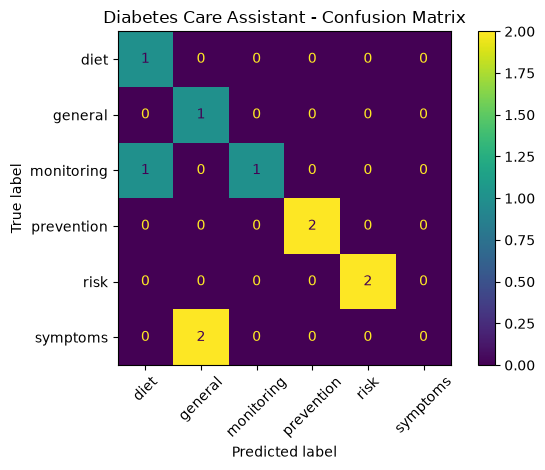

In [13]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

display.plot(xticks_rotation=45)
plt.title("Diabetes Care Assistant - Confusion Matrix")
plt.tight_layout()
plt.show()

## Cell 11 – Create the diabetes knowledge base

The assistant retrieves general educational information for each of its six supported intent categories.

In [14]:
knowledge_base = {
    "general": (
        "Diabetes is a group of health conditions involving high blood glucose. "
        "This can happen when the body does not make enough insulin or cannot use "
        "insulin effectively. Common types include type 1, type 2 and gestational diabetes."
    ),

    "symptoms": (
        "Possible symptoms include increased thirst, frequent urination, increased hunger, "
        "tiredness, blurred vision and unexplained weight loss. Some people have no obvious "
        "symptoms. Only an appropriate medical test can help diagnose diabetes."
    ),

    "risk": (
        "Risk factors for type 2 diabetes can include family history, overweight or obesity, "
        "physical inactivity, increasing age and a history of gestational diabetes. A risk "
        "factor does not mean that a person definitely has diabetes."
    ),

    "prevention": (
        "For many people, type 2 diabetes risk can be reduced through regular physical activity, "
        "balanced eating, and maintaining a healthy weight. Type 1 diabetes currently has no "
        "established prevention method."
    ),

    "diet": (
        "A balanced eating pattern may include vegetables, pulses, whole grains, fibre-rich "
        "foods and suitable protein sources. Limit sugary drinks and highly processed foods. "
        "Food choices should be adjusted with help from a qualified healthcare professional "
        "or dietitian when needed."
    ),

    "monitoring": (
        "Blood glucose may be checked using a blood glucose meter or a continuous glucose "
        "monitor. An HbA1c test gives information about average blood glucose over roughly "
        "the previous three months. Testing frequency and personal targets should be discussed "
        "with a healthcare professional."
    )
}

print("Knowledge base created for", len(knowledge_base), "intent categories.")

Knowledge base created for 6 intent categories.


## Cell 12 – Implement rule-based reasoning

Rules are checked before returning a normal knowledge-base answer:
1. Emergency escalation.
2. Medication and insulin dose safety.
3. Unsupported healthcare topic handling.
4. Low-confidence query handling.
5. Intent-based knowledge retrieval.
6. Educational disclaimer.

This is a simple keyword-based demonstration. It cannot detect every possible emergency or medical situation.

In [15]:
emergency_phrases = [
    "chest pain",
    "difficulty breathing",
    "trouble breathing",
    "unconscious",
    "seizure",
    "unable to wake",
    "severe confusion",
    "cannot wake",
    "not responding",
    "very low blood sugar",
    "severe hypoglycemia"
]

unsupported_topics = [
    "cancer",
    "asthma",
    "migraine",
    "arthritis",
    "heart disease",
    "kidney disease",
    "skin infection"
]

medication_phrases = [
    "dosage",
    "dose",
    "how much insulin",
    "increase my insulin",
    "change my insulin",
    "how many units of insulin"
]

def contains_phrase(text, phrase_list):
    return any(phrase in text for phrase in phrase_list)


def generate_response(user_query):
    query = user_query.lower().strip()

    # Rule 1: Emergency escalation
    if contains_phrase(query, emergency_phrases):
        return (
            "POSSIBLE EMERGENCY\n\n"
            "This message may describe a medical emergency. Contact local emergency "
            "services or seek emergency medical care now. Do not wait for an online "
            "assistant to assess the situation."
        )

    # Rule 2: Do not give medication or insulin dosing instructions
    if contains_phrase(query, medication_phrases):
        return (
            "MEDICATION SAFETY\n\n"
            "This assistant cannot recommend or calculate medicine or insulin doses, "
            "or advise changing a treatment plan. Please contact your doctor or diabetes "
            "care team for individual advice."
        )

    # Rule 3: Handle clearly unsupported health topics
    if contains_phrase(query, unsupported_topics):
        return (
            "UNSUPPORTED HEALTHCARE QUERY\n\n"
            "This assistant is designed for general diabetes-care information only. "
            "Please consult a qualified healthcare professional for advice about this topic."
        )

    # NLP preprocessing and TF-IDF conversion
    processed_query = preprocess(user_query)
    query_vector = tfidf.transform([processed_query])

    # A zero vector means none of the query's terms matched the learned vocabulary.
    if query_vector.nnz == 0:
        return (
            "LOW CONFIDENCE\n\n"
            "I could not understand this question. Please ask a clear question about "
            "diabetes information, symptoms, risk factors, prevention, diet or monitoring."
        )

    # Rule 4: Check similarity and classifier confidence
    similarity = cosine_similarity(query_vector, X_train_tfidf).max()
    probabilities = model.predict_proba(query_vector)[0]
    confidence = max(probabilities)

    if similarity < 0.10 or confidence < 0.20:
        return (
            "LOW CONFIDENCE\n\n"
            "I am not confident that I understood your question. Please rephrase it "
            "as a question about diabetes information, symptoms, risk factors, prevention, "
            "diet or blood glucose monitoring."
        )

    # Rule 5: Predict intent and retrieve information
    predicted_intent = model.predict(query_vector)[0]
    information = knowledge_base[predicted_intent]

    # Rule 6: Add an educational disclaimer
    return (
        "Detected intent: " + predicted_intent.upper() +
        "\nModel confidence: " + str(round(confidence * 100, 1)) + "%" +
        "\n\n" + information +
        "\n\nEducational information only. This assistant does not diagnose or "
        "replace advice from a qualified healthcare professional."
    )

print("Rule-based reasoning is ready.")

Rule-based reasoning is ready.


## Cell 13 – Integrate the cognitive assistant

This function connects the input query, preprocessing, classification, rules and knowledge retrieval.

In [16]:
def diabetes_assistant(user_query):
    if not user_query or not user_query.strip():
        return "Please enter a question."
    return generate_response(user_query)

question = "What are the symptoms of diabetes?"
print("User:", question)
print("\nAssistant:")
print(diabetes_assistant(question))

User: What are the symptoms of diabetes?

Assistant:
Detected intent: SYMPTOMS
Model confidence: 26.6%

Possible symptoms include increased thirst, frequent urination, increased hunger, tiredness, blurred vision and unexplained weight loss. Some people have no obvious symptoms. Only an appropriate medical test can help diagnose diabetes.

Educational information only. This assistant does not diagnose or replace advice from a qualified healthcare professional.


## Cell 14 – Test one query from each intent category

In [17]:
intent_test_queries = [
    "What is diabetes?",
    "How can I identify diabetes?",
    "Can family history increase diabetes risk?",
    "How can I reduce the risk of type 2 diabetes?",
    "What foods should people with diabetes eat?",
    "How can I check my blood glucose?"
]

for question in intent_test_queries:
    print("\nUser:", question)
    print("Assistant:", diabetes_assistant(question))
    print("-" * 65)


User: What is diabetes?
Assistant: Detected intent: GENERAL
Model confidence: 32.4%

Diabetes is a group of health conditions involving high blood glucose. This can happen when the body does not make enough insulin or cannot use insulin effectively. Common types include type 1, type 2 and gestational diabetes.

Educational information only. This assistant does not diagnose or replace advice from a qualified healthcare professional.
-----------------------------------------------------------------

User: How can I identify diabetes?
Assistant: Detected intent: SYMPTOMS
Model confidence: 26.6%

Possible symptoms include increased thirst, frequent urination, increased hunger, tiredness, blurred vision and unexplained weight loss. Some people have no obvious symptoms. Only an appropriate medical test can help diagnose diabetes.

Educational information only. This assistant does not diagnose or replace advice from a qualified healthcare professional.
---------------------------------------

## Cell 15 – Test the additional required cases

The four cases include a differently worded question, an unsupported healthcare topic, an unrelated low-confidence query and a possible emergency query.

In [18]:
additional_test_queries = [
    "I am thirsty all the time and keep going to the bathroom.",
    "What are the symptoms of cancer?",
    "Blue clouds are whispering near the window.",
    "A person with diabetes is unconscious."
]

for question in additional_test_queries:
    print("\nUser:", question)
    print("Assistant:", diabetes_assistant(question))
    print("-" * 65)


User: I am thirsty all the time and keep going to the bathroom.
Assistant: Detected intent: SYMPTOMS
Model confidence: 24.6%

Possible symptoms include increased thirst, frequent urination, increased hunger, tiredness, blurred vision and unexplained weight loss. Some people have no obvious symptoms. Only an appropriate medical test can help diagnose diabetes.

Educational information only. This assistant does not diagnose or replace advice from a qualified healthcare professional.
-----------------------------------------------------------------

User: What are the symptoms of cancer?
Assistant: UNSUPPORTED HEALTHCARE QUERY

This assistant is designed for general diabetes-care information only. Please consult a qualified healthcare professional for advice about this topic.
-----------------------------------------------------------------

User: Blue clouds are whispering near the window.
Assistant: LOW CONFIDENCE

I could not understand this question. Please ask a clear question about

## Cell 16 – Deploy an interactive Gradio interface

Enter one question per line to submit multiple questions in one go. Run this cell in Google Colab and open the Gradio link shown in the output.

In [19]:
def chatbot(user_input):
    if not user_input or not user_input.strip():
        return "Please enter at least one question."

    questions = [q.strip() for q in user_input.splitlines() if q.strip()]
    answers = []

    for number, question in enumerate(questions, start=1):
        answer = diabetes_assistant(question)
        answers.append(
            f"QUESTION {number}: {question}\n\nASSISTANT:\n{answer}"
        )

    return "\n\n" + ("-" * 60) + "\n\n".join(answers)


demo = gr.Interface(
    fn=chatbot,
    inputs=gr.Textbox(
        lines=5,
        label="Enter your question(s)",
        placeholder="What is diabetes?\nHow can blood sugar be monitored?"
    ),
    outputs=gr.Textbox(
        lines=18,
        label="Diabetes Care Assistant"
    ),
    title="Diabetes Care Information Assistant",
    description=(
        "An educational NLP and machine-learning assistant for general "
        "diabetes information. Enter one or more questions, one per line. "
        "Not for diagnosis or treatment."
    )
)

demo.launch(share=True)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://bb8e29e97f03837589.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Conclusion / Result

The Diabetes Care Information Assistant was developed using Python, Natural Language Processing and machine learning. The system uses a labelled corpus of 48 queries across six intents, a hierarchical taxonomy, domain concepts and relationships, NLP preprocessing, TF-IDF and a Multinomial Naive Bayes classifier. It evaluates the classifier using accuracy, precision, recall, F1-score and a confusion matrix. A knowledge base and rule-based checks are integrated into an interactive Gradio application.

**Limitations:** The corpus is small and created for a classroom demonstration. The model is not clinically validated, and keyword rules cannot identify every emergency or unsupported query. Do not use it for diagnosis, treatment decisions or medication dosing.